# Exploring the California Housing dataset

This notebook takes a first look at the data before any modelling. This stage is called **exploratory data analysis (EDA)**: getting to know what the data contains, how it is distributed, and whether anything needs cleaning.

## 1. Load the data

`fetch_california_housing` downloads the dataset the first time it runs and reuses the saved copy after that. Passing `as_frame=True` returns it as a pandas **DataFrame**, a table with named columns.

`data.frame` holds the full table: 8 feature columns plus the target, `MedHouseVal` (median house value, in units of $100,000). Each row is one census block group, a small neighbourhood.

`df.head()` shows the first 5 rows, a quick check that the data loaded as expected.

In [10]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df=data.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Summarise the numbers

`df.describe()` calculates summary statistics for every numeric column:

- `count`: how many values the column has.
- `mean`: the average.
- `std`: the standard deviation, a measure of how spread out the values are.
- `min` and `max`: the smallest and largest values.
- `25%`, `50%`, `75%`: the values below which a quarter, half and three quarters of the rows fall. The `50%` row is the **median**.

This is a quick way to spot odd values. Here, the `max` of `MedHouseVal` is 5.00001 and the `max` of `HouseAge` is 52: both columns were capped when the data was collected.

In [11]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## 3. Show every column and read the documentation

The tables above hide the middle columns behind `...` because pandas shortens wide tables by default. `pd.set_option("display.max_columns", None)` removes that limit, so `df.head()` now shows all 9 columns.

`data.DESCR` is the description that ships with the dataset. It explains what each column means, where the data came from, and the units of the target.

In [12]:
pd.set_option("display.max_columns",None)
print(data.DESCR)
df.head()


.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 4. Check for missing values

Real datasets often have gaps: cells where no value was recorded. pandas shows these as `NaN` ("not a number"). Most machine learning models cannot handle `NaN`, so we check for gaps before going any further.

`df.isna()` returns a table of the same shape, with `True` wherever a value is missing. `.sum()` then adds up each column, counting `True` as 1 and `False` as 0. The result is the number of missing values per column.

The documentation above says "Missing Attribute Values: None". This cell confirms it: a column of zeros means the dataset is complete and needs no cleaning for missing data.

In [13]:
# isna() marks each missing cell as True; sum() counts the Trues per column
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

## 5. Plot a histogram of house prices

A **histogram** shows how values are spread out. It splits the range of prices into equal-width intervals called **bins**, then draws one bar per bin. The taller the bar, the more block groups have a price in that interval.

We plot `MedHouseVal` because it is the **target**: the value a model will later try to predict. Knowing its shape first helps us choose and judge a model.

Things to look for in the plot:

- **Where the peak is**: the most common price range.
- **A long tail to the right**: a few expensive areas stretch the plot out. This is called a *right-skewed* distribution.
- **A tall spike at the far right (5.0)**: values above $500,000 were all recorded as $500,001, so they pile up in the last bar. This is the cap we saw in the `max` row of `describe()`.

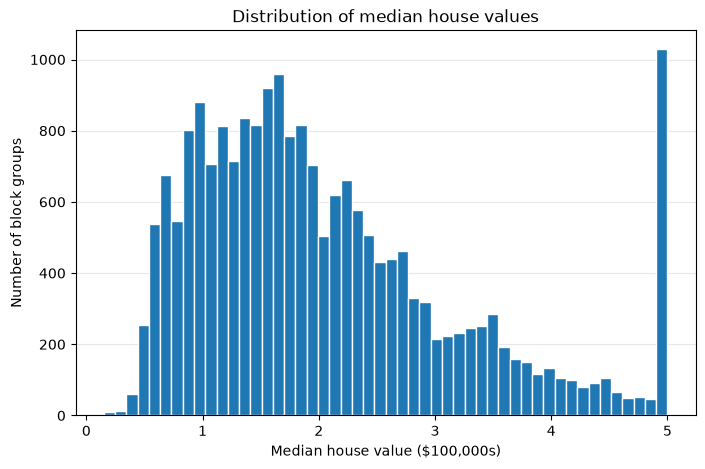

In [14]:

import pandas as pd
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
# bins=50 splits the price range into 50 equal-width bars
ax.hist(df["MedHouseVal"], bins=50, edgecolor="white")

ax.set_title("Distribution of median house values")
ax.set_xlabel("Median house value ($100,000s)")
ax.set_ylabel("Number of block groups")

# Faint horizontal guide lines, drawn behind the bars
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.show()

## correlation 
MedHouseVal

In [15]:
df.corr()["MedHouseVal"].sort_values()


Latitude      -0.144160
AveBedrms     -0.046701
Longitude     -0.045967
Population    -0.024650
AveOccup      -0.023737
HouseAge       0.105623
AveRooms       0.151948
MedInc         0.688075
MedHouseVal    1.000000
Name: MedHouseVal, dtype: float64

## Scatter plot
yes

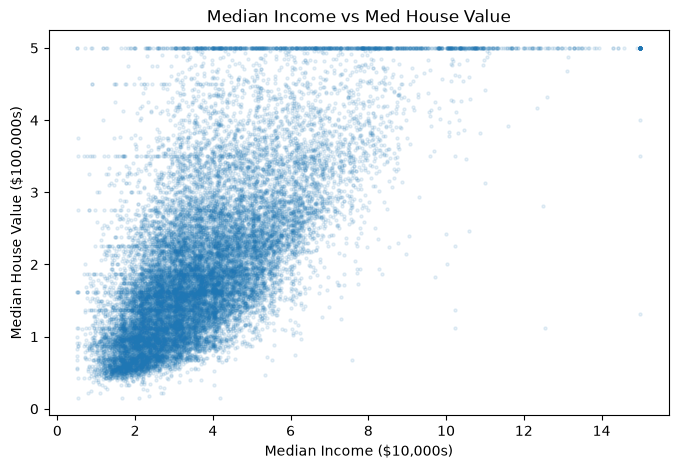

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.1, s=5)
ax.set_title("Median Income vs Med House Value")
ax.set_xlabel("Median Income ($10,000s)")
ax.set_ylabel("Median House Value ($100,000s)")
plt.show()


## Scatter Plot of Longitude vs Latitude
location also matters the price

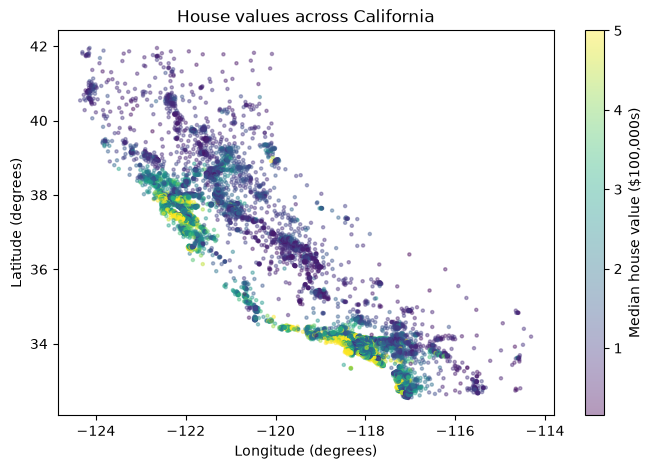

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))

# c= colours each dot by its house value; cmap picks the colour scale
points = ax.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    cmap="viridis",
    alpha=0.4,
    s=5,
)

# The colorbar shows which colour means which house value
fig.colorbar(points, ax=ax, label="Median house value ($100,000s)")

ax.set_title("House values across California")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
plt.show()

## Rooms
rooms are a weaker feature than income and location

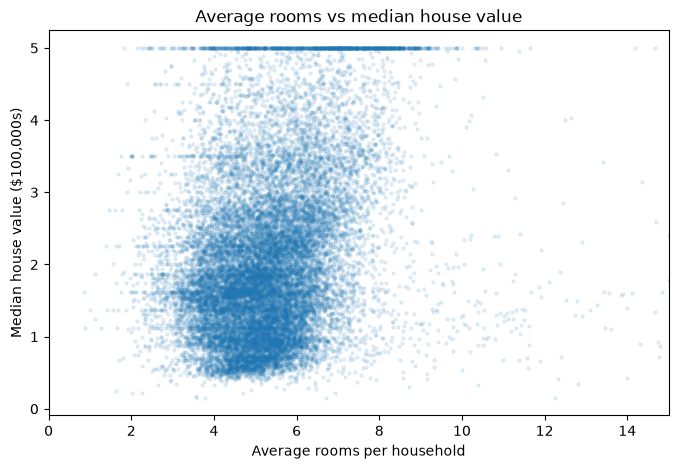

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))

# One dot per block group; alpha makes overlapping dots show as darker areas
ax.scatter(df["AveRooms"], df["MedHouseVal"], alpha=0.1, s=5)

# A few block groups average over 100 rooms; zoom in on the typical range
ax.set_xlim(0, 15)

ax.set_title("Average rooms vs median house value")
ax.set_xlabel("Average rooms per household")
ax.set_ylabel("Median house value ($100,000s)")
plt.show()